# R17 · Evaluación de la segmentación

**Proyecto Final Integrador · Machine Learning I · Universidad EAN**
Integrantes: Claudia Naranjo, Yery Pedraza y Nicolás Ruiz.

¿Se adopta la segmentación de R15 (K-means, k = 2, D-32), contrastada en R16? Se mide si se
reproduce, si separa un desenlace que no se usó para formarla y qué conserva un mapa de PCA. Se
resume en [`evaluacion_R17.md`](evaluacion_R17.md).

| Sección | Criterio de R17 |
|---|---|
| §1 Estabilidad | 20 particiones en mitades; mediana y rango del ARI; comparación con k = 3 y con Ward |
| §2 Validación externa | Tasa de tardías posteriores por segmento, con intervalo, eventos y prueba contra el azar |
| §3 PCA | Varianza, cargas y ARI entre la segmentación original y la del espacio proyectado |

k, la preparación y los centros se fijaron en R15, **antes de mirar el desenlace**. **Confidencialidad:**
solo cifras agregadas.

## 0. Configuración

In [1]:
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datos_crudos").is_dir())
sys.path.insert(0, str(RAIZ / "src"))

from cartera import datos
from cartera import segmentacion as sg
from cartera.config import SEMILLA

np.random.seed(SEMILLA)
print("Semilla", SEMILLA, "| Python", sys.version.split()[0], "| pandas", pd.__version__,
      "| numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__,
      "| matplotlib", matplotlib.__version__)

Semilla 2026 | Python 3.14.7 | pandas 3.0.6 | numpy 2.5.3 | scikit-learn 1.9.1 | scipy 1.18.1 | matplotlib 3.11.2


In [2]:
from scipy.cluster.hierarchy import fcluster, linkage
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

saldos, movs = datos.leer_todo()
perfil = sg.perfil(saldos, movs)
ent, prueba = sg.particion(perfil, SEMILLA)
prep = sg.preparacion().fit(ent[sg.VARIABLES])
Z, Z_pr = prep.transform(ent[sg.VARIABLES]), prep.transform(prueba[sg.VARIABLES])
km = KMeans(sg.K, n_init=sg.N_INIT, random_state=SEMILLA).fit(Z)
# Numeración por atraso mediano: 0 = paga a tiempo o casi, 1 = paga tarde
orden = np.argsort([np.median(ent.atraso_mediano.to_numpy()[km.labels_ == g]) for g in range(sg.K)])
renum = np.argsort(orden)
NOMBRES = {0: "paga a tiempo o casi", 1: "paga tarde"}
seg_ent = pd.Series(renum[km.labels_], index=ent.index)
seg_pr = pd.Series(renum[km.predict(Z_pr)], index=prueba.index)
print("Entrenamiento:", seg_ent.map(NOMBRES).value_counts().to_dict(), "| prueba:", seg_pr.map(NOMBRES).value_counts().to_dict())

Entrenamiento: {'paga a tiempo o casi': 120, 'paga tarde': 38} | prueba: {'paga a tiempo o casi': 51, 'paga tarde': 17}


## 1. Estabilidad con 20 particiones en mitades

En cada repetición, los clientes de entrenamiento se parten al azar en dos mitades. Con cada mitad
se ajusta de nuevo la preparación y el agrupamiento, y los dos modelos asignan a **todos** los
clientes de entrenamiento. El ARI entre esas dos asignaciones dice si la segmentación se reproduce
con otra muestra: 1 = idéntica. Se compara k = 2 con k = 3 y con Ward cortado en 2.

In [3]:
def ajustar(datos_ajuste, metodo, k):
    pr = sg.preparacion().fit(datos_ajuste[sg.VARIABLES])
    Za = pr.transform(datos_ajuste[sg.VARIABLES])
    Zt = pr.transform(ent[sg.VARIABLES])
    if metodo == "kmeans":
        return KMeans(k, n_init=sg.N_INIT, random_state=SEMILLA).fit(Za).predict(Zt)
    # Ward: cada cliente de entrenamiento va al centroide más cercano de los grupos de la mitad
    etq = fcluster(linkage(Za, method="ward"), t=k, criterion="maxclust")
    centros = np.array([Za[etq == g].mean(axis=0) for g in np.unique(etq)])
    return np.argmin(((Zt[:, None, :] - centros[None]) ** 2).sum(axis=2), axis=1)

rng = np.random.default_rng(SEMILLA)
variantes = {"K-means, k = 2 (elegido)": ("kmeans", 2), "K-means, k = 3": ("kmeans", 3), "Ward, 2 grupos": ("ward", 2)}
aris = {v: [] for v in variantes}
for _ in range(20):
    perm = rng.permutation(len(ent))
    a, b = ent.iloc[perm[: len(ent) // 2]], ent.iloc[perm[len(ent) // 2:]]
    for v, (metodo, k) in variantes.items():
        aris[v].append(adjusted_rand_score(ajustar(a, metodo, k), ajustar(b, metodo, k)))
pd.DataFrame({v: {"ARI mediana": np.median(x), "ARI mínimo": np.min(x), "ARI máximo": np.max(x)}
              for v, x in aris.items()}).T.round(3)

,ARI mediana,ARI mínimo,ARI máximo
"K-means, k = 2 (elegido)",0.652,0.317,0.890
"K-means, k = 3",0.385,0.172,0.678
"Ward, 2 grupos",0.456,0.097,0.870


## 2. Validación con un desenlace externo

**Desenlace:** las facturas de cada cliente emitidas desde el 1/07/2025 con desenlace conocido al
18/10/2026, y cuántas fueron tardías (más de 30 días de atraso). No se usó para formar los grupos:
el perfil solo ve facturas emitidas hasta el 30/06/2025.

Para cada segmento se reporta la tasa de facturas tardías con su **intervalo de Wilson del 95 %**,
el número de eventos (facturas tardías), de facturas y de clientes. Se mide en los clientes de
entrenamiento y en los de prueba.

**Prueba contra el azar:** como las facturas de un mismo cliente no son independientes, la prueba
principal es de **permutación por cliente**: se reparte al azar la etiqueta de segmento entre los
clientes 5.000 veces y se mira con qué frecuencia la diferencia de tasas es tan grande como la
observada. El chi cuadrado por factura se reporta como complemento; es optimista, porque trata cada
factura como independiente.

In [4]:
from scipy.stats import chi2_contingency

posterior = sg.desenlace_posterior(saldos, movs)

def wilson(eventos, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = eventos / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - margen, centro + margen

def tabla(segmentos, nombre_conjunto):
    d = posterior.join(segmentos.rename("segmento"), how="inner")
    filas = []
    for s, g in d.groupby("segmento"):
        ev, n = int(g.tardias.sum()), int(g.facturas.sum())
        lo, hi = wilson(ev, n)
        filas.append({"conjunto": nombre_conjunto, "segmento": NOMBRES[s], "clientes con facturas posteriores": len(g),
                      "facturas": n, "tardías (eventos)": ev, "tasa (%)": ev / n * 100,
                      "IC 95 % inferior": lo * 100, "IC 95 % superior": hi * 100})
    return d, pd.DataFrame(filas)

def permutacion(d, veces=5000):
    def dif(seg):
        t = d.assign(s=seg).groupby("s")[["tardias", "facturas"]].sum()
        r = t.tardias / t.facturas
        return r.loc[1] - r.loc[0]
    obs = dif(d.segmento.to_numpy())
    rng = np.random.default_rng(SEMILLA)
    nulas = np.array([dif(rng.permutation(d.segmento.to_numpy())) for _ in range(veces)])
    return obs, (np.abs(nulas) >= abs(obs)).mean()

resultados, pruebas = [], []
for segmentos, nombre in [(seg_ent, "entrenamiento"), (seg_pr, "prueba")]:
    d, t = tabla(segmentos, nombre)
    resultados.append(t)
    obs, p_perm = permutacion(d)
    contingencia = d.groupby("segmento")[["tardias", "facturas"]].sum()
    contingencia = np.column_stack([contingencia.tardias, contingencia.facturas - contingencia.tardias])
    chi2, p_chi, _, _ = chi2_contingency(contingencia)
    pruebas.append({"conjunto": nombre, "diferencia de tasas (puntos)": obs * 100,
                    "p por permutación de clientes": p_perm, "chi cuadrado por factura": chi2, "p del chi cuadrado": p_chi})
pd.concat(resultados).set_index(["conjunto", "segmento"]).round(1)

clientes con facturas posteriores  \
conjunto      segmento                                                  
entrenamiento paga a tiempo o casi                                 85   
              paga tarde                                           23   
prueba        paga a tiempo o casi                                 36   
              paga tarde                                           10   

                                    facturas  tardías (eventos)  tasa (%)  \
conjunto      segmento                                                      
entrenamiento paga a tiempo o casi      1869                455      24.3   
              paga tarde                 389                292      75.1   
prueba        paga a tiempo o casi       755                259      34.3   
              paga tarde                 227                182      80.2   

                                    IC 95 % inferior  IC 95 % superior  
conjunto      segmento                                                  
entrenamiento paga a tiempo o casi              22.5              26.3  
              paga tarde                        70.5              79.1  
prueba        paga a tiempo o casi              31.0              37.8  
              paga tarde                        74.5              84.8

In [5]:
pd.DataFrame(pruebas).set_index("conjunto").round(4)

,diferencia de tasas (puntos),p por permutación de clientes,chi cuadrado por factura,p del chi cuadrado
conjunto,,,,
entrenamiento,50.7197,0.0000,371.8670,0.0
prueba,45.8716,0.0006,146.5865,0.0


In [6]:
pd.Series({
    "Clientes de entrenamiento sin facturas posteriores": int((~seg_ent.index.isin(posterior.index)).sum()),
    "Clientes de prueba sin facturas posteriores": int((~seg_pr.index.isin(posterior.index)).sum()),
}).to_frame("clientes")

,clientes
Clientes de entrenamiento sin facturas posteriores,50
Clientes de prueba sin facturas posteriores,22


## 3. Mapa con PCA

PCA se ajusta **solo con el entrenamiento**, en el espacio preparado. Describe; la evaluación de §1
y §2 se hizo en el espacio completo de las 7 variables.

In [7]:
pca = PCA(random_state=SEMILLA).fit(Z)
pd.DataFrame({"varianza explicada (%)": pca.explained_variance_ratio_ * 100,
              "acumulada (%)": np.cumsum(pca.explained_variance_ratio_) * 100},
             index=[f"CP{i + 1}" for i in range(len(sg.VARIABLES))]).round(1)

,varianza explicada (%),acumulada (%)
CP1,38.7,38.7
CP2,18.5,57.2
CP3,13.1,70.3
CP4,11.9,82.2
CP5,10.2,92.4
CP6,5.6,98.0
CP7,2.0,100.0


In [8]:
pd.DataFrame(pca.components_[:3].T, index=sg.VARIABLES, columns=["CP1", "CP2", "CP3"]).round(2)

,CP1,CP2,CP3
atraso_mediano,0.56,0.13,-0.12
atraso_iqr,0.51,0.10,-0.12
pct_tardias,0.53,0.11,-0.04
facturas_por_anio,-0.12,0.59,0.09
log_monto_mediano,0.09,-0.53,0.63
pct_varios_abonos,0.25,0.25,0.70
pct_cierre_nota,0.25,-0.52,-0.27


In [9]:
filas = []
for n in [2, 3]:
    P = pca.transform(Z)[:, :n]
    etq_pca = KMeans(sg.K, n_init=sg.N_INIT, random_state=SEMILLA).fit_predict(P)
    filas.append({"componentes": n, "varianza conservada (%)": pca.explained_variance_ratio_[:n].sum() * 100,
                  "ARI con la segmentación original": adjusted_rand_score(seg_ent, etq_pca)})
pd.DataFrame(filas).set_index("componentes").round(3)

,varianza conservada (%),ARI con la segmentación original
componentes,,
2,57.215,0.945
3,70.311,0.945


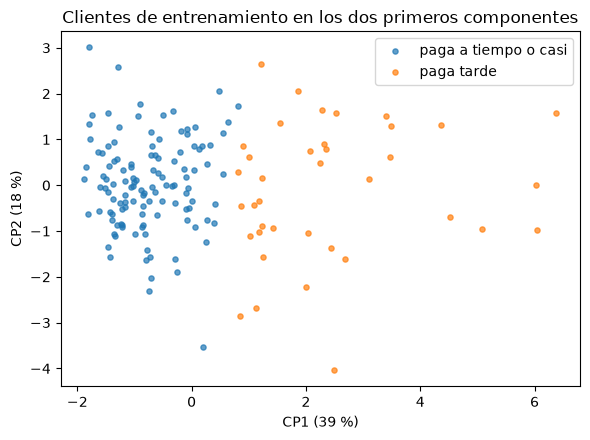

In [10]:
P = pca.transform(Z)
fig, ax = plt.subplots(figsize=(6, 4.5))
for s, nombre in NOMBRES.items():
    m = seg_ent.to_numpy() == s
    ax.scatter(P[m, 0], P[m, 1], s=14, alpha=0.7, label=nombre)
ax.set_xlabel(f"CP1 ({pca.explained_variance_ratio_[0] * 100:.0f} %)")
ax.set_ylabel(f"CP2 ({pca.explained_variance_ratio_[1] * 100:.0f} %)")
ax.legend(); ax.set_title("Clientes de entrenamiento en los dos primeros componentes")
plt.tight_layout(); plt.show()